<a href="https://colab.research.google.com/github/najafalinajaf449-hue/machine-learning/blob/main/lab09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: Najaf Ali <br>
Student ID: 023-24-0263 <br>
Section: H <br>
GitHub: https://github.com/najafalinajaf449-hue/machine-learninge<br>
Kaggle: https://www.kaggle.com/najaf2ali<br>
Dataset: Stroke Prediction Dataset (Kaggle) <br>
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

In [ ]:
!pip install -q imbalanced-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
SEED = 42

In [ ]:
df = pd.read_csv('/healthcare-dataset-stroke-data_1.csv')
print("Dataset shape")
print(df.shape)
print("First Five rows")
print(df.head())
print("Datatypes")
print(df.dtypes)

Dataset shape
(5110, 12)
First Five rows
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  
Datatypes
id   

In [ ]:
print("Missing Values")
print(df.isnull().sum())

print("Gender Counts")
print(df['gender'].value_counts())

print("Stroke Counts")
print(df['stroke'].value_counts())

print("Stroke Percentage")

print(df['stroke'].value_counts(normalize=True)*100)

Missing Values
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
Gender Counts
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
Stroke Counts
stroke
0    4861
1     249
Name: count, dtype: int64
Stroke Percentage
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [ ]:
# Remove gender category with too few rows
df = df[df["gender"] != "Other"].copy()

# Separate target and input features
X = df.drop(columns=["stroke"])
y = df["stroke"]

# Encode categorical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5109, 16)
Target shape: (5109,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = SEED,
    stratify = y
)

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nStroke cases in training set:", int(y_train.sum()))
print("Stroke cases in testing set:", int(y_test.sum()))

print("\nMissing values in training set:", X_train.isnull().sum().sum())
print("Missing values in testing set:", X_test.isnull().sum().sum())

Training shape: (4087, 16)
Testing shape: (1022, 16)

Stroke cases in training set: 199
Stroke cases in testing set: 50

Missing values in training set: 0
Missing values in testing set: 0


In [ ]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:")
display(X_train_scaled.head())

print("\nScaled testing data:")
display(X_test_scaled.head())

Scaled training data:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
845,-0.531583,0.209397,-0.323411,-0.245319,-0.821221,0.549234,-0.839671,0.717905,-0.062692,0.870980,-0.440434,-0.396402,0.994875,-0.460478,1.299544,-0.421272
3745,0.254340,-0.629845,-0.323411,-0.245319,-0.485884,-0.988900,-0.839671,-1.392942,-0.062692,0.870980,-0.440434,-0.396402,0.994875,-0.460478,1.299544,-0.421272
4184,-0.023100,-0.364822,-0.323411,-0.245319,0.302317,-0.769166,-0.839671,0.717905,-0.062692,0.870980,-0.440434,-0.396402,-1.005152,-0.460478,1.299544,-0.421272
3410,-0.388327,-0.232310,-0.323411,-0.245319,0.062342,0.497532,1.190942,0.717905,-0.062692,0.870980,-0.440434,-0.396402,-1.005152,-0.460478,1.299544,-0.421272
284,-0.482351,-1.292405,-0.323411,-0.245319,-0.527297,0.355351,1.190942,-1.392942,-0.062692,-1.148132,-0.440434,-0.396402,0.994875,-0.460478,-0.769500,-0.421272



Scaled testing data:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
3667,-1.547698,-0.674016,3.092042,-0.245319,-0.497748,0.975775,-0.839671,0.717905,-0.062692,-1.148132,-0.440434,-0.396402,-1.005152,-0.460478,1.299544,-0.421272
2217,-1.335082,-1.778282,-0.323411,-0.245319,-0.281950,-1.208633,-0.839671,-1.392942,-0.062692,-1.148132,-0.440434,2.522690,0.994875,-0.460478,-0.769500,-0.421272
374,1.027553,0.430250,-0.323411,-0.245319,-0.928896,0.277798,-0.839671,0.717905,-0.062692,-1.148132,-0.440434,-0.396402,-1.005152,-0.460478,-0.769500,2.373761
2392,0.470310,-0.364822,-0.323411,-0.245319,-0.820997,1.803007,1.190942,0.717905,-0.062692,0.870980,-0.440434,-0.396402,-1.005152,-0.460478,1.299544,-0.421272
299,-1.308907,0.651103,-0.323411,-0.245319,-0.259564,0.032214,-0.839671,0.717905,-0.062692,0.870980,-0.440434,-0.396402,-1.005152,-0.460478,-0.769500,-0.421272


In [ ]:
base_model= DummyClassifier(strategy='most_frequent')
base_model.fit(X_train, y_train)

y_pred_base = base_model.predict(X_test)
print("Base model accuracy: ", accuracy_score(y_test, y_pred_base))

Base model accuracy:  0.9510763209393346


In [ ]:
lr = LogisticRegression(random_state=SEED, max_iter=1000)
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print("PR AUC:", average_precision_score(y_test, y_prob))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9510763209393346
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC AUC: 0.5879218106995885
PR AUC: 0.08974562870041573

Confusion Matrix:
[[972   0]
 [ 50   0]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }

**Compare the accuracy of the baseline and Logistic Regression. What do you conclude?**<br>
The baseline model achieved an accuracy of 95.11%, while Logistic Regression achieved 90.31%. However, the baseline always predicts the majority class (stroke = 0) and cannot detect any stroke cases. Logistic Regression detects some stroke patients, but its recall is only 22%. Therefore, accuracy alone is misleading for this imbalanced dataset, and other evaluation metrics are necessary.<br>
**Look at the confusion matrix and recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?**<br>
The confusion matrix is [[912, 60], [39, 11]]. It shows 912 true negatives, 60 false positives, 39 false negatives, and 11 true positives. A false negative means that a patient who actually had a stroke was incorrectly predicted as having no stroke. This is important in a hospital because such patients may not be flagged for further assessment. Therefore, we should consider recall, precision, F1-score, ROC AUC, and PR AUC, rather than relying only on accuracy. Recall is particularly important because it measures the proportion of actual stroke cases detected by the model.

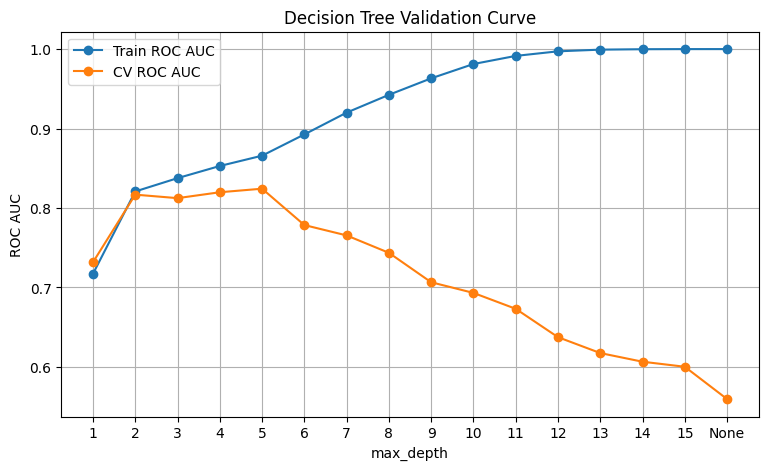

Best max_depth: 5
Best CV ROC AUC: 0.8242486872306923


In [ ]:
depths = list(range(1, 16)) + [None]

train_auc = []
cv_auc = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state = SEED)

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train, y_train)

    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))

    scores = cross_val_score(
        tree, X_train, y_train,
        cv=cv, scoring="roc_auc"
    )
    cv_auc.append(scores.mean())


plt.figure(figsize=(9, 5))
plt.plot(range(len(depths)), train_auc, marker="o", label="Train ROC AUC")
plt.plot(range(len(depths)), cv_auc, marker="o", label="CV ROC AUC")

plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[np.argmax(cv_auc)]
print("Best max_depth:", best_depth)
print("Best CV ROC AUC:", max(cv_auc))

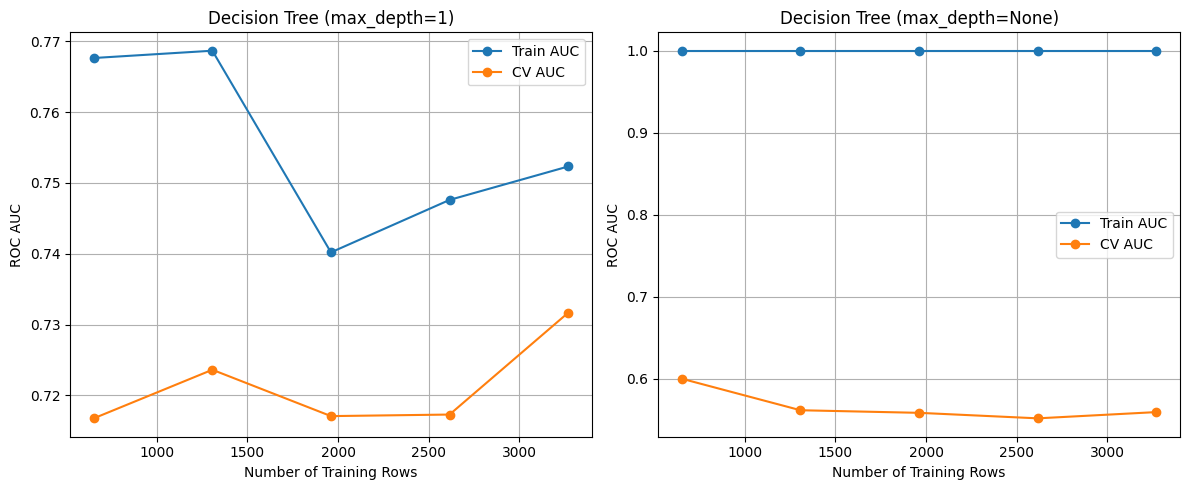

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes = np.linspace(0.2, 1.0, 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, depth in zip(axes, [1, None]):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)

    sizes, train_scores, cv_scores = learning_curve(
        tree,
        X_train,
        y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring="roc_auc",
        random_state=SEED
    )

    ax.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train AUC")
    ax.plot(sizes, cv_scores.mean(axis=1), marker="o", label="CV AUC")

    ax.set_title(f"Decision Tree (max_depth={depth})")
    ax.set_xlabel("Number of Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

depths = [1, 3, None]
rng = np.random.default_rng(SEED)

variance_results = []

for depth in depths:
    probs = []
    auc_scores = []

    for i in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)

        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        )
        tree.fit(X_boot, y_boot)

        y_prob = tree.predict_proba(X_test)[:, 1]
        probs.append(y_prob)
        auc_scores.append(roc_auc_score(y_test, y_prob))

    probs = np.array(probs)

    variance_results.append({
        "max_depth": str(depth),
        "Mean Prediction Variance": probs.var(axis=0).mean(),
        "Mean Test ROC AUC": np.mean(auc_scores),
        "AUC of Averaged Predictions": roc_auc_score(
            y_test, probs.mean(axis=0)
        )
    })

variance_df = pd.DataFrame(variance_results)
display(variance_df.round(4))

,max_depth,Mean Prediction Variance,Mean Test ROC AUC,AUC of Averaged Predictions
0,1,0.0007,0.7623,0.8132
1,3,0.0020,0.7928,0.8303
2,None,0.0442,0.5562,0.7665


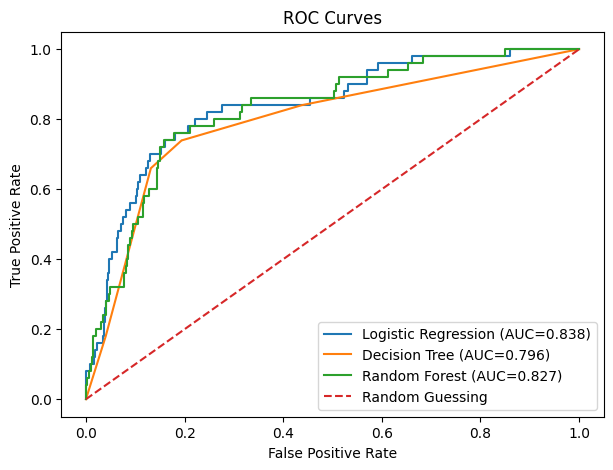

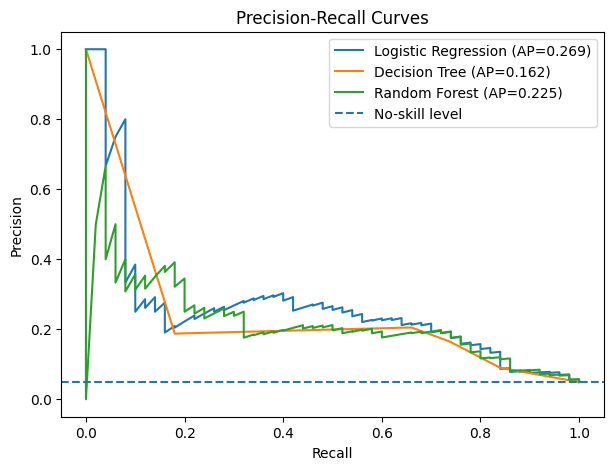

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

lr = LogisticRegression(random_state=SEED, max_iter=1000)
dt = DecisionTreeClassifier(max_depth=3, random_state=SEED)
rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

lr.fit(X_train_scaled, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

models = {
    "Logistic Regression": (lr, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "Random Forest": (rf, X_test)
}

# ROC curves
plt.figure(figsize=(7, 5))

for name, (model, X_eval) in models.items():
    y_prob = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random Guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

# Precision-Recall curves
plt.figure(figsize=(7, 5))

for name, (model, X_eval) in models.items():
    y_prob = model.predict_proba(X_eval)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.axhline(y_test.mean(), linestyle="--", label="No-skill level")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

In [ ]:
# Out-of-fold probabilities from training data
oof_prob = cross_val_predict(
    LogisticRegression(random_state=SEED, max_iter=1000),
    X_train_scaled,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Find the highest threshold with recall >= 0.80
thresholds = np.sort(np.unique(oof_prob))
valid_thresholds = []

for threshold in thresholds:
    recall = recall_score(
        y_train,
        (oof_prob >= threshold).astype(int),
        zero_division=0
    )

    if recall >= 0.80:
        valid_thresholds.append(threshold)

best_threshold = max(valid_thresholds)

print("Selected threshold:", best_threshold)

Selected threshold: 0.05002023466287502


In [ ]:
# Apply threshold to test probabilities
test_prob = lr.predict_proba(X_test_scaled)[:, 1]
y_pred_threshold = (test_prob >= best_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_threshold)

print("Test Recall:", recall_score(y_test, y_pred_threshold))
print("Test Precision:", precision_score(y_test, y_pred_threshold, zero_division=0))
print("Confusion Matrix:\n", cm)
print("Patients flagged:", int(y_pred_threshold.sum()))
print("False alarms:", int(cm[0, 1]))

Test Recall: 0.84
Test Precision: 0.134185303514377
Confusion Matrix:
 [[701 271]
 [  8  42]]
Patients flagged: 313
False alarms: 271


In [ ]:
results = []

methods = {
    "No Resampling": None,
    "Class Weight": "class_weight",
    "Undersampling": RandomUnderSampler(random_state=SEED),
    "Oversampling": RandomOverSampler(random_state=SEED),
    "SMOTE": SMOTE(random_state=SEED)
}

for model_name in ["Logistic Regression", "Random Forest"]:
    for method_name, sampler in methods.items():

        if model_name == "Logistic Regression":
            Xtr, Xte = X_train_scaled, X_test_scaled
        else:
            Xtr, Xte = X_train, X_test

        if method_name == "Class Weight":
            if model_name == "Logistic Regression":
                model = LogisticRegression(
                    random_state=SEED,
                    max_iter=1000,
                    class_weight="balanced"
                )
            else:
                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED,
                    class_weight="balanced"
                )

            X_res, y_res = Xtr, y_train

        else:
            if sampler is not None:
                X_res, y_res = sampler.fit_resample(Xtr, y_train)
            else:
                X_res, y_res = Xtr, y_train

            if model_name == "Logistic Regression":
                model = LogisticRegression(
                    random_state=SEED, max_iter=1000
                )
            else:
                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED
                )

        model.fit(X_res, y_res)

        y_pred = model.predict(Xte)
        y_prob = model.predict_proba(Xte)[:, 1]

        results.append({
            "Model": model_name,
            "Method": method_name,
            "Training Rows": len(X_res),
            "Training Stroke Cases": int(np.sum(y_res)),
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_prob),
            "PR AUC": average_precision_score(y_test, y_prob)
        })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Method,Training Rows,Training Stroke Cases,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,No Resampling,4087,199,1.0000,0.04,0.0769,0.8377,0.2687
1,Logistic Regression,Class Weight,4087,199,0.1325,0.80,0.2273,0.8375,0.2586
2,Logistic Regression,Undersampling,398,199,0.1194,0.80,0.2078,0.8329,0.2272
3,Logistic Regression,Oversampling,7776,3888,0.1329,0.80,0.2279,0.8364,0.2594
4,Logistic Regression,SMOTE,7776,3888,0.1322,0.78,0.2261,0.8378,0.2770
5,Random Forest,No Resampling,4087,199,0.0000,0.00,0.0000,0.8268,0.2254
6,Random Forest,Class Weight,4087,199,0.2791,0.24,0.2581,0.8251,0.2171
7,Random Forest,Undersampling,398,199,0.1037,0.84,0.1846,0.8062,0.1623
8,Random Forest,Oversampling,7776,3888,0.1897,0.22,0.2037,0.8147,0.2190
9,Random Forest,SMOTE,7776,3888,0.5000,0.06,0.1071,0.7909,0.1863


In [ ]:

# Combine the original training and test data
X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])

# Incorrect: apply SMOTE before the new split
smote = SMOTE(random_state=SEED)
X_smote_all, y_smote_all = smote.fit_resample(X_all, y_all)

# Split after SMOTE
X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = (
    train_test_split(
        X_smote_all,
        y_smote_all,
        test_size=0.20,
        random_state=SEED,
        stratify=y_smote_all
    )
)

rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

rf_wrong.fit(X_train_wrong, y_train_wrong)

y_pred_wrong = rf_wrong.predict(X_test_wrong)
y_prob_wrong = rf_wrong.predict_proba(X_test_wrong)[:, 1]

wrong_results = {
    "Method": "SMOTE before split (Incorrect)",
    "Precision": precision_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "Recall": recall_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "F1": f1_score(y_test_wrong, y_pred_wrong, zero_division=0),
    "ROC AUC": roc_auc_score(y_test_wrong, y_prob_wrong),
    "PR AUC": average_precision_score(y_test_wrong, y_prob_wrong)
}

correct_results = results_df[
    (results_df["Model"] == "Random Forest") &
    (results_df["Method"] == "SMOTE")
].iloc[0]

comparison = pd.DataFrame([
    {
        "Method": "SMOTE after split (Correct)",
        "Precision": correct_results["Precision"],
        "Recall": correct_results["Recall"],
        "F1": correct_results["F1"],
        "ROC AUC": correct_results["ROC AUC"],
        "PR AUC": correct_results["PR AUC"]
    },
    wrong_results
])

display(comparison.round(4))


,Method,Precision,Recall,F1,ROC AUC,PR AUC
0,SMOTE after split (Correct),0.5000,0.0600,0.1071,0.7909,0.1863
1,SMOTE before split (Incorrect),0.9957,0.9578,0.9764,0.9952,0.9962


In [ ]:

# Combine the original training and test data
X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])

# Incorrect: apply SMOTE before the new split
smote = SMOTE(random_state=SEED)
X_smote_all, y_smote_all = smote.fit_resample(X_all, y_all)

# Split after SMOTE
X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = (
    train_test_split(
        X_smote_all,
        y_smote_all,
        test_size=0.20,
        random_state=SEED,
        stratify=y_smote_all
    )
)

rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

rf_wrong.fit(X_train_wrong, y_train_wrong)

y_pred_wrong = rf_wrong.predict(X_test_wrong)
y_prob_wrong = rf_wrong.predict_proba(X_test_wrong)[:, 1]

wrong_results = {
    "Method": "SMOTE before split (Incorrect)",
    "Precision": precision_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "Recall": recall_score(
        y_test_wrong, y_pred_wrong, zero_division=0
    ),
    "F1": f1_score(y_test_wrong, y_pred_wrong, zero_division=0),
    "ROC AUC": roc_auc_score(y_test_wrong, y_prob_wrong),
    "PR AUC": average_precision_score(y_test_wrong, y_prob_wrong)
}

correct_results = results_df[
    (results_df["Model"] == "Random Forest") &
    (results_df["Method"] == "SMOTE")
].iloc[0]

comparison = pd.DataFrame([
    {
        "Method": "SMOTE after split (Correct)",
        "Precision": correct_results["Precision"],
        "Recall": correct_results["Recall"],
        "F1": correct_results["F1"],
        "ROC AUC": correct_results["ROC AUC"],
        "PR AUC": correct_results["PR AUC"]
    },
    wrong_results
])

display(comparison.round(4))

,Method,Precision,Recall,F1,ROC AUC,PR AUC
0,SMOTE after split (Correct),0.5000,0.0600,0.1071,0.7909,0.1863
1,SMOTE before split (Incorrect),0.9957,0.9578,0.9764,0.9952,0.9962


### (a) For Logistic Regression, what changed after resampling and what did NOT change?

Resampling generally increased recall but sometimes reduced precision. ROC AUC changed less because it measures how well the model ranks the classes rather than its predictions at one threshold.

### (b) Did Random Forest react to the methods in the same way as Logistic Regression?

No, both models reacted differently. Logistic Regression learns a linear boundary, while Random Forest learns nonlinear patterns. Therefore, resampling affected their results differently.

### (c) Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted?

Applying SMOTE before splitting can cause data leakage because synthetic samples may use information from future test patients. This can make evaluation results misleading, so SMOTE must be applied only to training data.

### (d) If you had to pick one rebalancing approach for this hospital, which would you pick and why?

I would choose the method that gives high recall with reasonable precision and PR AUC. In stroke screening, detecting more actual stroke cases is important, but too many false alarms can also create unnecessary follow-up tests.

,Noise Fraction,Logistic Regression,Decision Tree (depth 3),Decision Tree (None),Random Forest
0,0.00,0.8377,0.7956,0.5210,0.8268
1,0.05,0.8208,0.7889,0.5461,0.7939
2,0.10,0.8028,0.7864,0.5449,0.7490
3,0.20,0.7720,0.7080,0.5446,0.6818


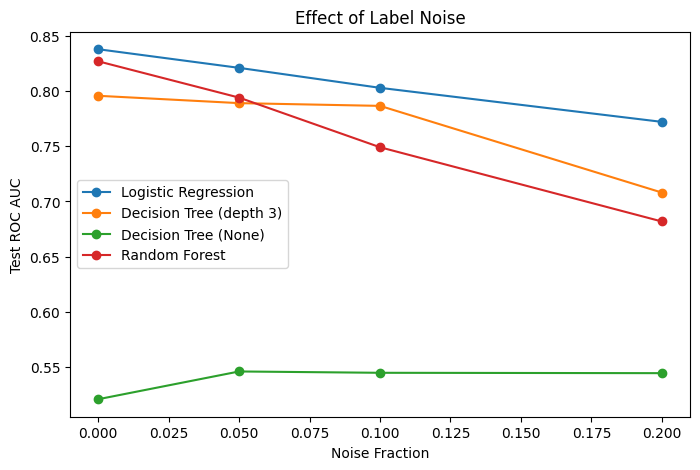

In [ ]:

def flip_labels(y, fraction, seed):
    rng = np.random.default_rng(seed)
    y_noisy = np.array(y).copy()
    n_flip = int(len(y_noisy) * fraction)
    idx = rng.choice(len(y_noisy), n_flip, replace=False)
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy

noise_levels = [0, 0.05, 0.10, 0.20]
label_results = []

for level in noise_levels:
    repeats = 1 if level == 0 else 5
    auc_runs = []

    for r in range(repeats):
        y_noisy = flip_labels(y_train, level, SEED + r)

        models_noise = {
            "Logistic Regression": (
                LogisticRegression(max_iter=1000, random_state=SEED),
                X_train_scaled, X_test_scaled
            ),
            "Decision Tree (depth 3)": (
                DecisionTreeClassifier(max_depth=3, random_state=SEED),
                X_train, X_test
            ),
            "Decision Tree (None)": (
                DecisionTreeClassifier(random_state=SEED),
                X_train, X_test
            ),
            "Random Forest": (
                RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED
                ),
                X_train, X_test
            )
        }

        run_auc = {}

        for name, (model, Xtr, Xte) in models_noise.items():
            model.fit(Xtr, y_noisy)
            prob = model.predict_proba(Xte)[:, 1]
            run_auc[name] = roc_auc_score(y_test, prob)

        auc_runs.append(run_auc)

    label_results.append({
        "Noise Fraction": level,
        **pd.DataFrame(auc_runs).mean().to_dict()
    })

label_df = pd.DataFrame(label_results)
display(label_df.round(4))

label_df.set_index("Noise Fraction").plot(
    marker="o", figsize=(8, 5)
)
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise")
plt.show()


,Noise Level,Logistic Regression,Decision Tree (depth 3),Decision Tree (None),Random Forest
0,0.0,0.8377,0.7956,0.5210,0.8268
1,0.5,0.8320,0.7972,0.5498,0.8036
2,1.0,0.8070,0.7576,0.5196,0.7755
3,2.0,0.7628,0.6942,0.5301,0.7338


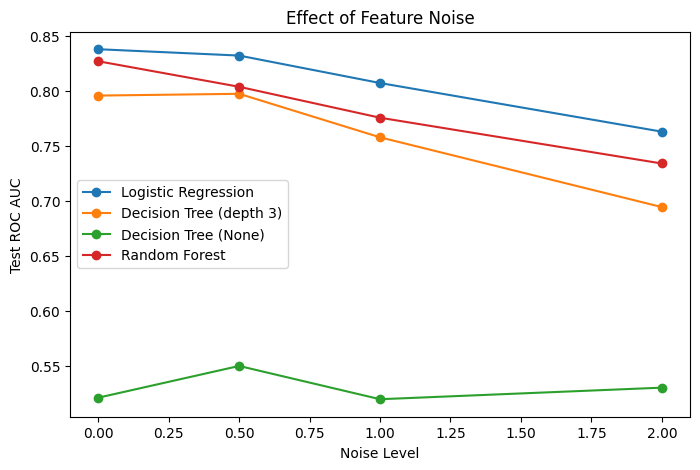

In [ ]:

feature_cols = ["age", "avg_glucose_level", "bmi"]
feature_levels = [0, 0.5, 1, 2]
feature_results = []

for level in feature_levels:
    auc_runs = []

    for r in range(5):
        rng = np.random.default_rng(SEED + r)
        X_noisy = X_train.copy()

        for col in feature_cols:
            noise = rng.normal(
                0, X_train[col].std() * level, len(X_train)
            )
            X_noisy[col] = X_noisy[col] + noise

        scaler_noise = StandardScaler()
        Xtr_scaled = pd.DataFrame(
            scaler_noise.fit_transform(X_noisy),
            columns=X_noisy.columns,
            index=X_noisy.index
        )
        Xte_scaled = pd.DataFrame(
            scaler_noise.transform(X_test),
            columns=X_test.columns,
            index=X_test.index
        )

        models_noise = {
            "Logistic Regression": (
                LogisticRegression(max_iter=1000, random_state=SEED),
                Xtr_scaled, Xte_scaled
            ),
            "Decision Tree (depth 3)": (
                DecisionTreeClassifier(max_depth=3, random_state=SEED),
                X_noisy, X_test
            ),
            "Decision Tree (None)": (
                DecisionTreeClassifier(random_state=SEED),
                X_noisy, X_test
            ),
            "Random Forest": (
                RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5,
                    random_state=SEED
                ),
                X_noisy, X_test
            )
        }

        run_auc = {}

        for name, (model, Xtr, Xte) in models_noise.items():
            model.fit(Xtr, y_train)
            prob = model.predict_proba(Xte)[:, 1]
            run_auc[name] = roc_auc_score(y_test, prob)

        auc_runs.append(run_auc)

    feature_results.append({
        "Noise Level": level,
        **pd.DataFrame(auc_runs).mean().to_dict()
    })

feature_df = pd.DataFrame(feature_results)
display(feature_df.round(4))

feature_df.set_index("Noise Level").plot(
    marker="o", figsize=(8, 5)
)
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise")
plt.show()


In [ ]:

smote_noise_results = []

for r in range(3):
    y_noisy = flip_labels(y_train, 0.10, SEED + r)

    for model_name in ["Logistic Regression", "Random Forest"]:
        if model_name == "Logistic Regression":
            Xtr, Xte = X_train_scaled, X_test_scaled
            model_class = LogisticRegression
            model_args = {"max_iter": 1000, "random_state": SEED}
        else:
            Xtr, Xte = X_train, X_test
            model_class = RandomForestClassifier
            model_args = {
                "n_estimators": 200,
                "min_samples_leaf": 5,
                "random_state": SEED
            }

        for use_smote in [False, True]:
            if use_smote:
                sampler = SMOTE(random_state=SEED)
                Xfit, yfit = sampler.fit_resample(Xtr, y_noisy)
            else:
                Xfit, yfit = Xtr, y_noisy

            model = model_class(**model_args)
            model.fit(Xfit, yfit)

            prob = model.predict_proba(Xte)[:, 1]

            smote_noise_results.append({
                "Repeat": r + 1,
                "Model": model_name,
                "Method": "With SMOTE" if use_smote else "Without SMOTE",
                "ROC AUC": roc_auc_score(y_test, prob),
                "PR AUC": average_precision_score(y_test, prob)
            })

smote_noise_df = pd.DataFrame(smote_noise_results)
display(smote_noise_df.round(4))

display(
    smote_noise_df.groupby(["Model", "Method"])[
        ["ROC AUC", "PR AUC"]
    ].mean().round(4)
)


,Repeat,Model,Method,ROC AUC,PR AUC
0,1,Logistic Regression,Without SMOTE,0.8112,0.2292
1,1,Logistic Regression,With SMOTE,0.8182,0.2533
2,1,Random Forest,Without SMOTE,0.7525,0.1817
3,1,Random Forest,With SMOTE,0.7052,0.1237
4,2,Logistic Regression,Without SMOTE,0.7952,0.2417
5,2,Logistic Regression,With SMOTE,0.7903,0.2455
6,2,Random Forest,Without SMOTE,0.7367,0.1255
7,2,Random Forest,With SMOTE,0.6903,0.1650
8,3,Logistic Regression,Without SMOTE,0.8161,0.1914
9,3,Logistic Regression,With SMOTE,0.8173,0.1912


ROC AUC  PR AUC
Model               Method                        
Logistic Regression With SMOTE      0.8086  0.2300
                    Without SMOTE   0.8075  0.2208
Random Forest       With SMOTE      0.6975  0.1361
                    Without SMOTE   0.7472  0.1507

### (a) Which model is most damaged by noise and which is most stable?

Compare the ROC AUC values at the highest noise levels. The model with the largest drop is most affected, while the model with the smallest drop is most stable. Deep trees can be sensitive to changes in training data.

### (b) Which hurts more: label noise or feature noise?

Compare the ROC AUC at comparable noise levels. Label noise changes the correct answers the model learns from, while feature noise changes input measurements. The larger decrease in ROC AUC indicates which type of noise was more damaging in this experiment.

### (c) What did SMOTE do when labels were noisy?

Compare ROC AUC and PR AUC with and without SMOTE. SMOTE can amplify label noise by creating synthetic minority samples from incorrectly labelled observations, potentially making the model learn misleading patterns.

In [ ]:
from sklearn.metrics import confusion_matrix

# Default threshold = 0.5
y_prob_final = lr.predict_proba(X_test_scaled)[:, 1]

y_pred_default = (y_prob_final >= 0.5).astype(int)
y_pred_chosen = (y_prob_final >= best_threshold).astype(int)

def final_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "False Alarms": cm[0, 1],
        "Missed Strokes": cm[1, 0]
    }

final_df = pd.DataFrame([
    {"Approach": "Default threshold (0.5)",
     **final_metrics(y_test, y_pred_default)},
    {"Approach": f"Chosen threshold ({best_threshold:.4f})",
     **final_metrics(y_test, y_pred_chosen)}
])

display(final_df.round(4))

,Approach,Precision,Recall,F1,False Alarms,Missed Strokes
0,Default threshold (0.5),1.0000,0.04,0.0769,0,48
1,Chosen threshold (0.0500),0.1342,0.84,0.2314,271,8
